In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import pandas as pd
import random

random.seed(42)

categories = {
    "Login Issue": [
        "I cannot login to my account",
        "My password is not working",
        "I forgot my password",
        "I am unable to access my account",
        "Login is failing",
        "I cannot sign in",
        "Password reset is not working",
        "My account login is blocked",
        "I am having trouble logging in",
        "The login page is not accepting my password"
    ],

    "Application Error": [
        "The application shows an error",
        "The software crashes when I save a file",
        "Application is showing an unexpected error",
        "The app stopped working suddenly",
        "I get an error while opening the application",
        "The application crashes frequently",
        "An error appears while saving data",
        "The software is not working correctly",
        "Application failed to process my request",
        "The system displays an application error"
    ],

    "Report": [
        "I need my monthly sales report",
        "Please generate the quarterly report",
        "I need the latest financial report",
        "Can you send me the monthly report",
        "I want to download my sales report",
        "Please provide the yearly report",
        "I need a customer report",
        "Generate the weekly sales report",
        "I want to view my transaction report",
        "Please send the latest business report"
    ],

    "Account Update": [
        "I want to change my phone number",
        "Please update my registered email address",
        "I need to change my contact information",
        "Please update my account details",
        "I want to update my registered mobile number",
        "I need to change my address",
        "Please update my personal information",
        "I want to modify my account details",
        "Please change my email address",
        "I need to update my contact number"
    ],

    "Performance": [
        "The application is very slow",
        "The website takes too long to load",
        "Application performance is very poor",
        "The system is responding slowly",
        "Pages are loading very slowly",
        "The application takes too long to open",
        "The website is extremely slow today",
        "System response time is very high",
        "The app is taking too long to respond",
        "The system performance is slow"
    ]
}

priorities = ["Low", "Medium", "High"]
statuses = ["Open", "Closed", "Pending"]

data = []

ticket_number = 1

for category, descriptions in categories.items():

    for i in range(50):

        description = random.choice(descriptions)
        priority = random.choice(priorities)
        status = random.choice(statuses)

        data.append([
            f"T{ticket_number:03d}",
            description,
            category,
            priority,
            status
        ])

        ticket_number += 1


df = pd.DataFrame(
    data,
    columns=[
        "ticket_id",
        "ticket_description",
        "category",
        "priority",
        "status"
    ]
)

print("Dataset created successfully!")
print("Number of records:", len(df))

df.head(10)

Dataset created successfully!
Number of records: 250


,ticket_id,ticket_description,category,priority,status
0,T001,My password is not working,Login Issue,Low,Pending
1,T002,Login is failing,Login Issue,Low,Open
2,T003,I forgot my password,Login Issue,High,Open
3,T004,I am having trouble logging in,Login Issue,Low,Pending
4,T005,Password reset is not working,Login Issue,Low,Open
5,T006,My password is not working,Login Issue,Low,Open
6,T007,I am having trouble logging in,Login Issue,High,Open
7,T008,I am having trouble logging in,Login Issue,Low,Pending
8,T009,I am having trouble logging in,Login Issue,Medium,Open
9,T010,My account login is blocked,Login Issue,High,Closed


In [ ]:
print(df["category"].value_counts())

category
Login Issue          50
Application Error    50
Report               50
Account Update       50
Performance          50
Name: count, dtype: int64


In [ ]:
df.to_csv("tickets.csv", index=False)

print("tickets.csv saved successfully!")

tickets.csv saved successfully!


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (250, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   ticket_id           250 non-null    object
 1   ticket_description  250 non-null    object
 2   category            250 non-null    object
 3   priority            250 non-null    object
 4   status              250 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
ticket_id             0
ticket_description    0
category              0
priority              0
status                0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
df.head(10)

,ticket_id,ticket_description,category,priority,status
0,T001,My password is not working,Login Issue,Low,Pending
1,T002,Login is failing,Login Issue,Low,Open
2,T003,I forgot my password,Login Issue,High,Open
3,T004,I am having trouble logging in,Login Issue,Low,Pending
4,T005,Password reset is not working,Login Issue,Low,Open
5,T006,My password is not working,Login Issue,Low,Open
6,T007,I am having trouble logging in,Login Issue,High,Open
7,T008,I am having trouble logging in,Login Issue,Low,Pending
8,T009,I am having trouble logging in,Login Issue,Medium,Open
9,T010,My account login is blocked,Login Issue,High,Closed


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["clean_description"] = df["ticket_description"].apply(clean_text)

df[["ticket_description", "clean_description"]].head(10)

,ticket_description,clean_description
0,My password is not working,my password is not working
1,Login is failing,login is failing
2,I forgot my password,i forgot my password
3,I am having trouble logging in,i am having trouble logging in
4,Password reset is not working,password reset is not working
5,My password is not working,my password is not working
6,I am having trouble logging in,i am having trouble logging in
7,I am having trouble logging in,i am having trouble logging in
8,I am having trouble logging in,i am having trouble logging in
9,My account login is blocked,my account login is blocked


In [ ]:
print(df.columns)

Index(['ticket_id', 'ticket_description', 'category', 'priority', 'status',
       'clean_description'],
      dtype='object')


In [ ]:
# Total number of tickets
print("Total Tickets:", len(df))

# Tickets by category
print("\nTickets by Category:")
print(df["category"].value_counts())

Total Tickets: 250

Tickets by Category:
category
Login Issue          50
Application Error    50
Report               50
Account Update       50
Performance          50
Name: count, dtype: int64


In [ ]:
print("Tickets by Priority:")
print(df["priority"].value_counts())

Tickets by Priority:
priority
Low       97
High      77
Medium    76
Name: count, dtype: int64


In [ ]:
print("Tickets by Status:")
print(df["status"].value_counts())

Tickets by Status:
status
Pending    91
Open       85
Closed     74
Name: count, dtype: int64


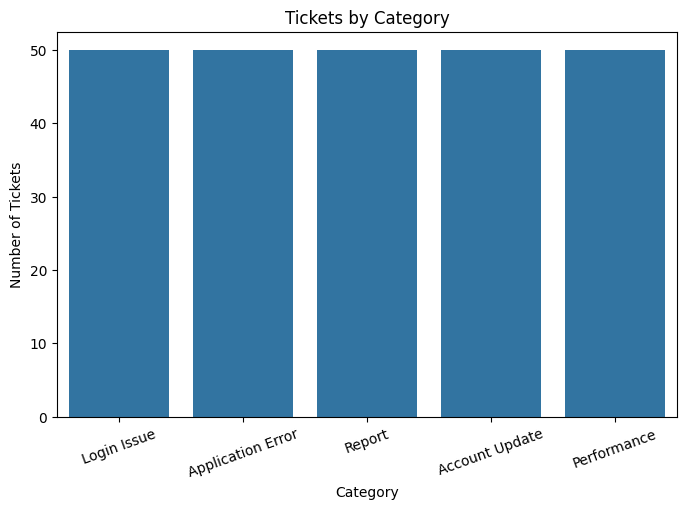

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="category")

plt.title("Tickets by Category")
plt.xlabel("Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=20)

plt.show()

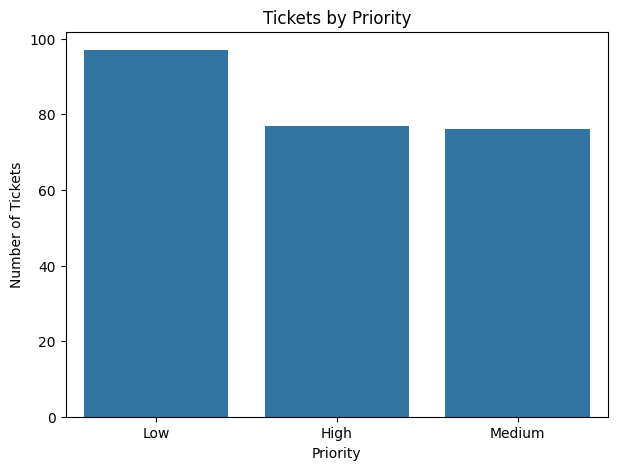

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="priority")

plt.title("Tickets by Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X = df["clean_description"]
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 200
Testing records: 50


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (200, 108)
Testing TF-IDF shape: (50, 108)


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test_tfidf)

print("Prediction completed!")
print(y_pred[:10])

Prediction completed!
['Performance' 'Account Update' 'Application Error' 'Application Error'
 'Account Update' 'Report' 'Performance' 'Application Error' 'Performance'
 'Application Error']


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


In [ ]:
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

Accuracy : 100.0 %
Precision: 100.0 %
Recall   : 100.0 %
F1 Score : 100.0 %


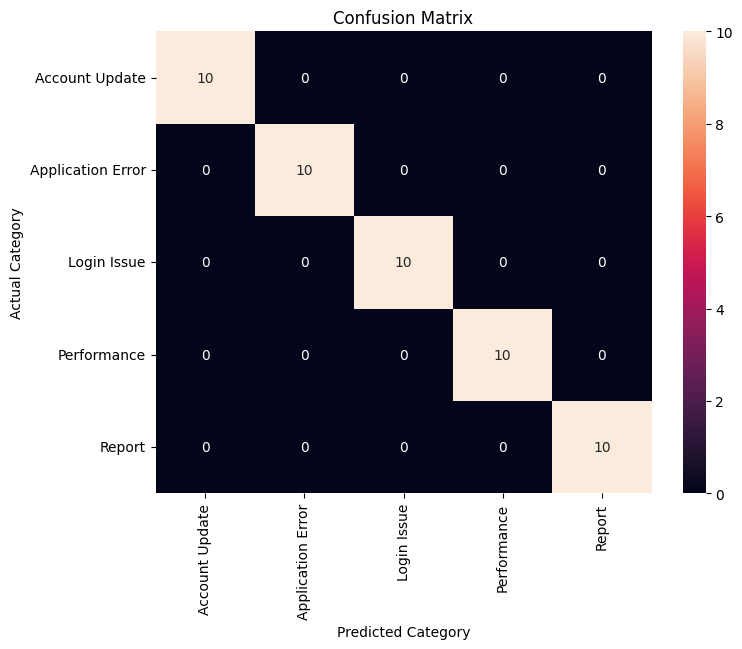

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

In [ ]:
new_tickets = [
    "I forgot my password and cannot login to my account",
    "The application crashes whenever I try to open it",
    "I need a monthly sales report",
    "Please update my phone number in my account",
    "The application is running very slowly"
]

new_tickets_clean = [clean_text(ticket) for ticket in new_tickets]

new_tickets_tfidf = vectorizer.transform(new_tickets_clean)

predictions = model.predict(new_tickets_tfidf)

for i in range(len(new_tickets)):
    print("Ticket:", new_tickets[i])
    print("Predicted Category:", predictions[i])
    print("-" * 50)

Ticket: I forgot my password and cannot login to my account
Predicted Category: Login Issue
--------------------------------------------------
Ticket: The application crashes whenever I try to open it
Predicted Category: Application Error
--------------------------------------------------
Ticket: I need a monthly sales report
Predicted Category: Report
--------------------------------------------------
Ticket: Please update my phone number in my account
Predicted Category: Account Update
--------------------------------------------------
Ticket: The application is running very slowly
Predicted Category: Performance
--------------------------------------------------


In [ ]:
probabilities = model.predict_proba(new_tickets_tfidf)

for i in range(len(new_tickets)):
    confidence = max(probabilities[i]) * 100

    print("Ticket:", new_tickets[i])
    print("Predicted Category:", predictions[i])
    print("Confidence:", round(confidence, 2), "%")
    print("-" * 50)

Ticket: I forgot my password and cannot login to my account
Predicted Category: Login Issue
Confidence: 85.55 %
--------------------------------------------------
Ticket: The application crashes whenever I try to open it
Predicted Category: Application Error
Confidence: 48.52 %
--------------------------------------------------
Ticket: I need a monthly sales report
Predicted Category: Report
Confidence: 83.43 %
--------------------------------------------------
Ticket: Please update my phone number in my account
Predicted Category: Account Update
Confidence: 69.85 %
--------------------------------------------------
Ticket: The application is running very slowly
Predicted Category: Performance
Confidence: 71.6 %
--------------------------------------------------


In [ ]:
import joblib

In [ ]:
joblib.dump(model, "ticket_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


In [ ]:
loaded_model = joblib.load("ticket_model.pkl")
loaded_vectorizer = joblib.load("tfidf_vectorizer.pkl")

test_ticket = "I cannot login to my account"

test_clean = clean_text(test_ticket)

test_vector = loaded_vectorizer.transform([test_clean])

prediction = loaded_model.predict(test_vector)

print("Ticket:", test_ticket)
print("Predicted Category:", prediction[0])

Ticket: I cannot login to my account
Predicted Category: Login Issue


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                   precision    recall  f1-score   support

   Account Update       1.00      1.00      1.00        10
Application Error       1.00      1.00      1.00        10
      Login Issue       1.00      1.00      1.00        10
      Performance       1.00      1.00      1.00        10
           Report       1.00      1.00      1.00        10

         accuracy                           1.00        50
        macro avg       1.00      1.00      1.00        50
     weighted avg       1.00      1.00      1.00        50



In [ ]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results[results["Actual"] != results["Predicted"]])

Empty DataFrame
Columns: [Actual, Predicted]
Index: []
